## MixedGraph Visualization

This notebook demonstrates the `MixedGraph` class, which supports both directed and undirected edges in a single graph. We build a 5-node example and render it with `lcn.core.plotting.plot_graph` (matplotlib + NetworkX).

Edges are distinguished both by style and by color:
- **Red, with arrows** = directed edges
- **Blue, no arrowheads** = undirected edges

In [1]:
from lcn.core.mixed_graph import MixedGraph

# Create a 5-node mixed graph
mg = MixedGraph()
mg.add_nodes_from(["A", "B", "C", "D", "E"])

# Directed edges (will render with arrows in red)
mg.add_directed_edge("A", "B", color="red")
mg.add_directed_edge("A", "C", color="red")
mg.add_directed_edge("D", "E", color="red")

# Undirected edges (will render in blue)
mg.add_undirected_edge("B", "C", color="blue")
mg.add_undirected_edge("C", "D", color="blue")
mg.add_undirected_edge("B", "D", color="blue")

print(mg)

MixedGraph with 5 nodes, 3 directed edges, 3 undirected edges


### Render the graph

`plot_graph` accepts a `MixedGraph` directly: directed edges are drawn with arrowheads and undirected edges as plain lines, using each edge's `color` attribute.

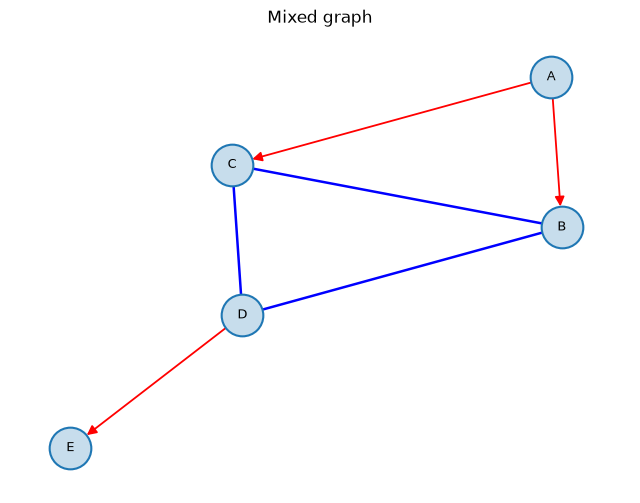

In [2]:
%matplotlib inline
from lcn.core.plotting import plot_graph

plot_graph(mg, title="Mixed graph");

### Explore the graph

The `MixedGraph` API provides queries that respect the distinction between directed and undirected edges.

In [3]:
print("Neighbors of C:", set(mg.neighbors("C")))
print("Successors of A:", set(mg.successors("A")))
print("Predecessors of B:", set(mg.predecessors("B")))
print("Degree of C:", mg.degree("C"))
print("Connected:", mg.is_connected())

Neighbors of C: {'B', 'A', 'D'}
Successors of A: {'C', 'B'}
Predecessors of B: {'A'}
Degree of C: 3
Connected: True


In [4]:
# Get the connected components (undirected)
cliques = mg.get_undirected_cliques()
print("Connected components (undirected):", cliques)

Connected components (undirected): [['D', 'C', 'B']]
